# Cross-dataset generalization: UAH-DriveSet -> Zenodo Driving Events

**Idea:** train a small model on UAH only, then test it, without any retraining, on a different dataset
(Zenodo "Driving Events", Escotta & Beccaro, 2022, CC BY 4.0, DOI 10.5281/zenodo.6570972).

**Why a smaller model?** The Zenodo files have no GPS speed and their axes are not the same as UAH's,
so we use only two orientation-free signals that exist in both datasets:
1. `dyn_acc`  - size of the acceleration vector with gravity/slow drift removed (m/s^2)
2. `rot_rate` - size of the rotation-rate vector (rad/s)

**Classes (3):** 0 = No event, 1 = Turning, 2 = Braking/Acceleration (merged, because without a known
heading they cannot be told apart reliably).

Run the cells from top to bottom.

In [2]:
# ===== Cell 1: imports and settings =====
import os, re, glob, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (f1_score, balanced_accuracy_score, accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

# ---------- PATHS (edit only if your folders are different) ----------
UAH_DIR = Path(r"C:\Users\ASUS\Desktop\SRM KTR\B-tech_computer_science\semester-5\MLT\Driver-Behavior-and-Driving-Risk-Recognition\UAH-DRIVESET-v1\UAH-DRIVESET-v1")
_candidates = [Path.cwd() / "zenodo_dataset", Path.cwd() / "external_validation" / "zenodo_dataset"]
ZEN_DIR = next((p for p in _candidates if p.exists()), None)
OUT_DIR = Path.cwd() / "generalization_outputs"
OUT_DIR.mkdir(exist_ok=True)

print("UAH folder exists :", UAH_DIR.exists())
print("Zenodo folder     :", ZEN_DIR)
print("Outputs go to     :", OUT_DIR)
assert UAH_DIR.exists(), "UAH_DIR is wrong - fix the path above"
assert ZEN_DIR is not None, "zenodo_dataset folder not found next to this notebook"

# ---------- SETTINGS ----------
SEED = 42
DT = 0.1            # 10 Hz, same as UAH
WINDOW = 20         # samples per window = 2 s
STEP = 10           # 50% overlap
G = 9.80665         # g -> m/s^2
HP_WIN = 50         # 5 s rolling mean used to remove gravity / slow drift
MIN_OVERLAP = 0.5   # a Zenodo window gets an event label if >= 50% of it lies inside that event
LANE_CHANGE_AS = "drop"   # "drop" = ignore lane-change windows, "turn" = count them as Turning
CLASS_NAMES = {0: "No event", 1: "Turning", 2: "Braking/Acceleration"}
LABELS = [0, 1, 2]

UAH folder exists : True
Zenodo folder     : c:\Users\ASUS\Desktop\SRM KTR\B-tech_computer_science\semester-5\MLT\Driver-Behavior-and-Driving-Risk-Recognition\notebooks\external_validation\zenodo_dataset
Outputs go to     : c:\Users\ASUS\Desktop\SRM KTR\B-tech_computer_science\semester-5\MLT\Driver-Behavior-and-Driving-Risk-Recognition\notebooks\external_validation\generalization_outputs


In [3]:
# ===== Cell 2: load the Zenodo trips and find the correct label time shift =====
def highpass(a):
    """Remove slow components (gravity, drift) from an (n,3) array."""
    s = pd.DataFrame(a)
    return (s - s.rolling(HP_WIN, center=True, min_periods=1).mean()).values


def to_10hz(df, grid):
    """Average the fast sensor readings into 0.1 s bins and fill small gaps."""
    idx = np.floor(df["t"].values / DT).astype(int)
    g = df[["x", "y", "z"]].groupby(idx).mean()
    return g.reindex(grid).interpolate(limit_direction="both").values


def load_zenodo_trip(i):
    lin = pd.read_csv(ZEN_DIR / f"Linear_Acceleration_{i}.csv")
    gyr = pd.read_csv(ZEN_DIR / f"Gyroscope_{i}.csv")
    lab = pd.read_csv(ZEN_DIR / f"Labeled_events_{i}.csv")
    lin.columns = ["t", "x", "y", "z"]
    gyr.columns = ["t", "x", "y", "z"]
    lo = int(np.floor(max(lin.t.min(), gyr.t.min()) / DT))
    hi = int(np.floor(min(lin.t.max(), gyr.t.max()) / DT))
    grid = np.arange(lo, hi + 1)
    acc = to_10hz(lin, grid)
    rot = to_10hz(gyr, grid)
    rot = rot - np.median(rot, axis=0)                  # remove constant gyro bias
    return {"trip": i, "t": grid * DT, "lab": lab,
            "dyn_acc": np.linalg.norm(highpass(acc), axis=1),
            "rot_rate": np.linalg.norm(rot, axis=1)}


def contrast(sig, t, lab, codes, shift):
    """Mean signal inside the events divided by mean outside. Big number = good alignment."""
    m = np.zeros(len(t), bool)
    for _, r in lab[lab.target.isin(codes)].iterrows():
        m |= (t >= r.start + shift) & (t <= r.end + shift)
    if m.sum() < 5 or (~m).sum() < 5:
        return np.nan
    return sig[m].mean() / sig[~m].mean()


zen = [load_zenodo_trip(i) for i in (1, 2, 3)]

rows = []
for z in zen:
    ts = float(z["lab"].timesync.iloc[0])
    cand = {"0": 0.0, "+timesync": ts, "-timesync": -ts}
    res = {k: contrast(z["rot_rate"], z["t"], z["lab"], [1, 2], v) for k, v in cand.items()}
    best = max(res, key=lambda k: -1 if np.isnan(res[k]) else res[k])
    z["shift"] = cand[best]
    scan = {s: contrast(z["rot_rate"], z["t"], z["lab"], [1, 2], s) for s in np.arange(-8, 8.01, 0.25)}
    gbest = max(scan, key=lambda s: -1 if np.isnan(scan[s]) else scan[s])
    rows.append({"trip": z["trip"], "timesync": ts,
                 "turn contrast @0": round(res["0"], 2),
                 "@+timesync": round(res["+timesync"], 2),
                 "@-timesync": round(res["-timesync"], 2),
                 "CHOSEN shift (s)": z["shift"],
                 "best of fine scan (s)": gbest,
                 "scan contrast": round(scan[gbest], 2),
                 "braking/accel contrast (dyn_acc)": round(contrast(z["dyn_acc"], z["t"], z["lab"], [4, 5], z["shift"]), 2)})
align = pd.DataFrame(rows)
print(align.to_string(index=False))
print("\nHow to read this: 'turn contrast' = rotation rate inside turns / outside turns.")
print("A value clearly above 1 (e.g. 1.5-3) means the labels line up with the sensor data at that shift.")
print("If CHOSEN shift and 'best of fine scan' disagree by a lot, tell your guide/me before continuing.")

 trip  timesync  turn contrast @0  @+timesync  @-timesync  CHOSEN shift (s)  best of fine scan (s)  scan contrast  braking/accel contrast (dyn_acc)
    1    11.123              6.24        1.26        1.15               0.0                   0.25           6.24                              2.03
    2     4.948              4.81        1.13        1.10               0.0                   0.25           4.83                              1.46
    3     4.019              5.69        1.07        0.92               0.0                  -0.25           5.70                              1.63

How to read this: 'turn contrast' = rotation rate inside turns / outside turns.
A value clearly above 1 (e.g. 1.5-3) means the labels line up with the sensor data at that shift.
If CHOSEN shift and 'best of fine scan' disagree by a lot, tell your guide/me before continuing.


In [4]:
# ===== Cell 3: Zenodo windows (features + labels) =====
def window_features(dyn, rot):
    f = {}
    for name, x in (("dyn_acc", dyn), ("rot_rate", rot)):
        f[f"{name}_mean"] = x.mean()
        f[f"{name}_std"] = x.std()
        f[f"{name}_min"] = x.min()
        f[f"{name}_max"] = x.max()
        f[f"{name}_range"] = x.max() - x.min()
    return f


def zenodo_windows(z):
    n = len(z["t"])
    ev = z["lab"].copy()
    ev["s"] = ev.start + z["shift"]
    ev["e"] = ev.end + z["shift"]
    rows = []
    for s in range(0, n - WINDOW + 1, STEP):
        t0 = z["t"][s]
        t1 = t0 + WINDOW * DT
        ov = ((np.minimum(t1, ev.e) - np.maximum(t0, ev.s)).clip(lower=0)) / (WINDOW * DT)
        if ov.max() == 0:
            lab = 0                                   # no labelled event nearby
        else:
            k = ov.idxmax()
            code, frac = int(ev.loc[k, "target"]), ov.max()
            if frac < MIN_OVERLAP:
                lab = -1                              # only partly inside an event -> ambiguous, ignored
            elif code == 0:
                lab = 0                               # non-aggressive event counts as "no (aggressive) event"
            elif code in (1, 2):
                lab = 1                               # right / left turn
            elif code in (4, 5):
                lab = 2                               # braking / acceleration
            else:
                lab = 1 if LANE_CHANGE_AS == "turn" else -1
        f = window_features(z["dyn_acc"][s:s + WINDOW], z["rot_rate"][s:s + WINDOW])
        rows.append({"trip": z["trip"], "label": lab, **f})
    return pd.DataFrame(rows)


zen_all = pd.concat([zenodo_windows(z) for z in zen], ignore_index=True)
FEATS = [c for c in zen_all.columns if c not in ("trip", "label")]
zdf = zen_all[zen_all.label >= 0].reset_index(drop=True)

print("Features used:", FEATS)
print("\nZenodo windows per trip and label (-1 = ignored):")
print(pd.crosstab(zen_all.trip, zen_all.label))
print("\nWindows kept for testing:", len(zdf), "of", len(zen_all))
print((zdf.label.map(CLASS_NAMES).value_counts()).to_string())
zen_all.to_csv(OUT_DIR / "zenodo_windows.csv", index=False)

Features used: ['dyn_acc_mean', 'dyn_acc_std', 'dyn_acc_min', 'dyn_acc_max', 'dyn_acc_range', 'rot_rate_mean', 'rot_rate_std', 'rot_rate_min', 'rot_rate_max', 'rot_rate_range']

Zenodo windows per trip and label (-1 = ignored):
label   -1     0    1   2
trip                     
1      183  1100  160  98
2      118   430   52  45
3      231  1257   36  27

Windows kept for testing: 3205 of 3737
label
No event                2787
Turning                  248
Braking/Acceleration     170


In [5]:
# ===== Cell 4: UAH windows with the SAME two signals =====
ACC_COLS = ["t", "active", "ax", "ay", "az", "ax_kf", "ay_kf", "az_kf", "roll", "pitch", "yaw"]
UAH_TO_3 = {0: 0, 1: 2, 2: 1, 3: 2}       # UAH: 1 Braking, 2 Turning, 3 Acceleration


def read_txt(path, names):
    if not path.exists() or path.stat().st_size == 0:
        return None
    df = pd.read_csv(path, sep=r"\s+", header=None, engine="python", on_bad_lines="skip")
    df = df.iloc[:, :len(names)]
    df.columns = names[:df.shape[1]]
    return df


def uah_window_label(ev, t0, t1):
    if ev is None or len(ev) == 0:
        return 0
    inside = ev[(ev["t"] >= t0) & (ev["t"] <= t1)]
    if len(inside) == 0:
        return 0
    row = inside.sort_values("level", ascending=False).iloc[0]
    return int(row["type"]) if int(row["type"]) in (1, 2, 3) else 0


pattern = re.compile(r"-(D\d)-(NORMAL|AGGRESSIVE|DROWSY)\d*-(MOTORWAY|SECONDARY)", re.IGNORECASE)
rows = []
n_trips = 0
for d in sorted(UAH_DIR.glob("D[1-6]")):
    for trip_dir in sorted(d.iterdir()):
        m = pattern.search(trip_dir.name)
        if not trip_dir.is_dir() or not m:
            continue
        acc = read_txt(trip_dir / "RAW_ACCELEROMETERS.txt", ACC_COLS)
        ev = read_txt(trip_dir / "EVENTS_INERTIAL.txt", ["t", "type", "level"])
        if acc is None:
            continue
        n_trips += 1
        acc = acc.drop_duplicates(subset="t").sort_values("t").reset_index(drop=True)
        acc = acc.interpolate(limit_direction="both")
        t = acc["t"].values
        a = acc[["ax_kf", "ay_kf", "az_kf"]].values * G                      # g -> m/s^2
        dyn = np.linalg.norm(highpass(a), axis=1)
        ang = np.unwrap(acc[["roll", "pitch", "yaw"]].values, axis=0)     # UAH angles are already in radians
        rot = np.linalg.norm(np.gradient(ang, t, axis=0), axis=1)            # rad/s from orientation angles
        for s in range(0, len(t) - WINDOW + 1, STEP):
            lab = UAH_TO_3[uah_window_label(ev, t[s], t[s + WINDOW - 1])]
            f = window_features(dyn[s:s + WINDOW], rot[s:s + WINDOW])
            rows.append({"trip": trip_dir.name, "driver": m.group(1).upper(), "label": lab, **f})

uah = pd.DataFrame(rows)
print("UAH trips used:", n_trips, "| windows:", len(uah))
print(uah.label.map(CLASS_NAMES).value_counts().to_string())
print("\nQuick sanity check - feature medians (UAH vs Zenodo). Big differences are expected and explain the gap:")
print(pd.DataFrame({"UAH": uah[FEATS].median(), "Zenodo": zdf[FEATS].median()}).round(3).to_string())
uah.to_csv(OUT_DIR / "uah_common_features_3class.csv", index=False)

UAH trips used: 40 | windows: 31055
label
No event                29860
Braking/Acceleration      829
Turning                   366

Quick sanity check - feature medians (UAH vs Zenodo). Big differences are expected and explain the gap:
                  UAH  Zenodo
dyn_acc_mean    0.297   0.571
dyn_acc_std     0.125   0.262
dyn_acc_min     0.092   0.151
dyn_acc_max     0.570   1.179
dyn_acc_range   0.468   0.984
rot_rate_mean   0.028   0.041
rot_rate_std    0.012   0.017
rot_rate_min    0.009   0.010
rot_rate_max    0.057   0.083
rot_rate_range  0.045   0.065


In [6]:
# ===== Cell 5: train the common-feature model on UAH only =====
def partial_smote(y):
    c = Counter(y)
    target = int(0.25 * max(c.values()))            # raise minority classes to 25% of the majority
    return {k: target for k, v in c.items() if v < target}


def make_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("smote", SMOTE(sampling_strategy=partial_smote, k_neighbors=3, random_state=SEED)),
        ("model", HistGradientBoostingClassifier(
            learning_rate=0.1, max_iter=200, max_leaf_nodes=31,
            min_samples_leaf=40, l2_regularization=1.0,
            early_stopping=False, random_state=SEED)),
    ])


def macro_f1(y, p):
    return f1_score(y, p, labels=LABELS, average="macro", zero_division=0)


# --- reference: how good is this small model INSIDE UAH (unseen trips)? ---
Xu, yu, gu = uah[FEATS], uah.label.values, uah.trip.values
ref = []
for tr, te in GroupKFold(n_splits=3).split(Xu, yu, gu):
    m = make_model().fit(Xu.iloc[tr], yu[tr])
    ref.append(macro_f1(yu[te], m.predict(Xu.iloc[te])))
UAH_REF = float(np.mean(ref))
print("UAH reference (3-fold, unseen trips) macro-F1:", round(UAH_REF, 4), "| folds:", np.round(ref, 3))

# --- final model: all UAH windows ---
model_A = make_model().fit(Xu, yu)
print("Final common-feature model trained on", len(uah), "UAH windows.")

UAH reference (3-fold, unseen trips) macro-F1: 0.4463 | folds: [0.428 0.436 0.475]
Final common-feature model trained on 31055 UAH windows.


                               setting  macro_F1  balanced_acc  accuracy
  UAH -> UAH (unseen trips, reference)    0.4463           NaN       NaN
     Majority-class baseline on Zenodo    0.3101        0.3333    0.8696
   A) UAH -> Zenodo (strict zero-shot)    0.3726        0.5178    0.5763
B) UAH -> Zenodo (per-dataset z-score)    0.3895        0.3832    0.8222

=== A) classification report (strict zero-shot) ===
                      precision    recall  f1-score   support

            No event       0.96      0.60      0.74      2787
             Turning       0.14      0.25      0.18       248
Braking/Acceleration       0.12      0.71      0.20       170

            accuracy                           0.58      3205
           macro avg       0.41      0.52      0.37      3205
        weighted avg       0.85      0.58      0.66      3205

=== B) classification report (per-dataset z-score) ===
                      precision    recall  f1-score   support

            No event       

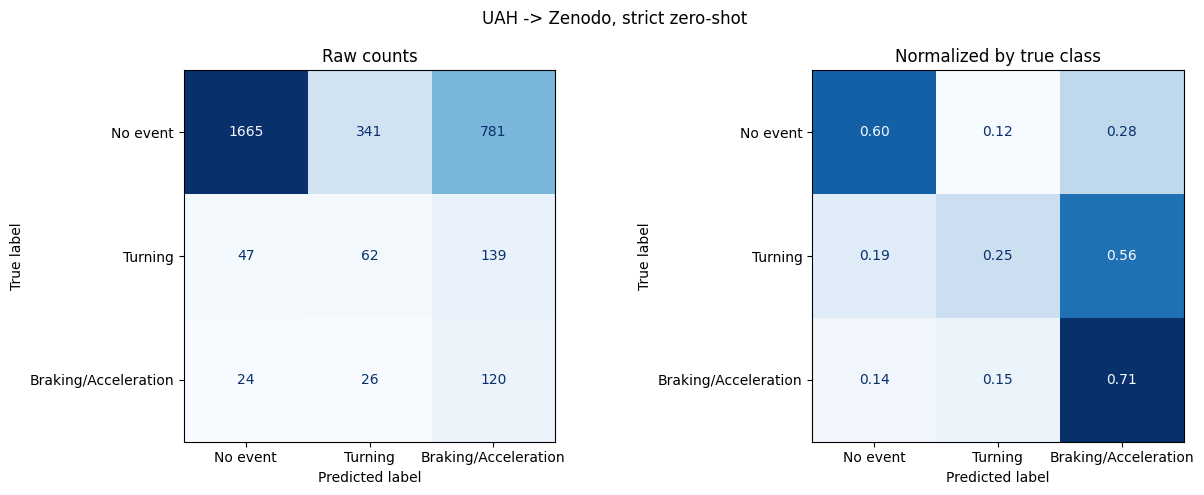

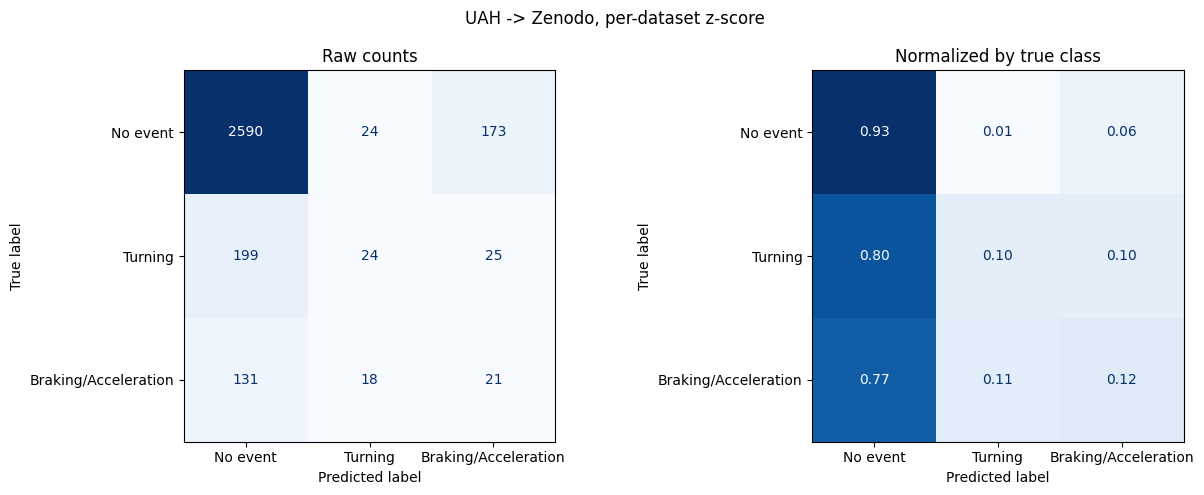

In [7]:
# ===== Cell 6: zero-shot test on Zenodo =====
Xz, yz = zdf[FEATS], zdf.label.values

def zscore(df):                      # per-dataset standardisation (uses features only, no labels)
    return (df - df.mean()) / df.std().replace(0, 1)

# Baseline: always predict "No event"
dummy = DummyClassifier(strategy="most_frequent").fit(Xu, yu)
BASE = macro_f1(yz, dummy.predict(Xz))

# A) strict zero-shot: model trained on UAH, applied to Zenodo as it is
predA = model_A.predict(Xz)

# B) label-free per-dataset standardisation (each dataset z-scored with its own statistics)
model_B = make_model().fit(zscore(Xu), yu)
predB = model_B.predict(zscore(Xz))

summary = pd.DataFrame([
    {"setting": "UAH -> UAH (unseen trips, reference)", "macro_F1": UAH_REF, "balanced_acc": np.nan, "accuracy": np.nan},
    {"setting": "Majority-class baseline on Zenodo",   "macro_F1": BASE, "balanced_acc": balanced_accuracy_score(yz, dummy.predict(Xz)), "accuracy": accuracy_score(yz, dummy.predict(Xz))},
    {"setting": "A) UAH -> Zenodo (strict zero-shot)",  "macro_F1": macro_f1(yz, predA), "balanced_acc": balanced_accuracy_score(yz, predA), "accuracy": accuracy_score(yz, predA)},
    {"setting": "B) UAH -> Zenodo (per-dataset z-score)", "macro_F1": macro_f1(yz, predB), "balanced_acc": balanced_accuracy_score(yz, predB), "accuracy": accuracy_score(yz, predB)},
]).round(4)
print(summary.to_string(index=False))

print("\n=== A) classification report (strict zero-shot) ===")
print(classification_report(yz, predA, labels=LABELS, target_names=[CLASS_NAMES[i] for i in LABELS], zero_division=0))
print("=== B) classification report (per-dataset z-score) ===")
print(classification_report(yz, predB, labels=LABELS, target_names=[CLASS_NAMES[i] for i in LABELS], zero_division=0))


def plot_cm(y, p, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    names = [CLASS_NAMES[i] for i in LABELS]
    ConfusionMatrixDisplay.from_predictions(y, p, labels=LABELS, display_labels=names, cmap="Blues",
                                            colorbar=False, ax=axes[0])
    axes[0].set_title("Raw counts")
    ConfusionMatrixDisplay.from_predictions(y, p, labels=LABELS, display_labels=names, cmap="Blues",
                                            normalize="true", values_format=".2f", colorbar=False, ax=axes[1])
    axes[1].set_title("Normalized by true class")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(OUT_DIR / fname, dpi=150)
    plt.show()

plot_cm(yz, predA, "UAH -> Zenodo, strict zero-shot", "confusion_zenodo_A_strict.png")
plot_cm(yz, predB, "UAH -> Zenodo, per-dataset z-score", "confusion_zenodo_B_zscore.png")
summary.to_csv(OUT_DIR / "zenodo_generalization_summary.csv", index=False)

In [8]:
# ===== Cell 7: per-trip results + small adaptation experiment =====
rows = []
for k in (1, 2, 3):
    te = (zdf.trip == k).values
    if te.sum() == 0:
        continue
    # adaptation: UAH + the OTHER two Zenodo trips, tested on trip k
    Xtr = pd.concat([Xu, Xz[~te]], ignore_index=True)
    ytr = np.r_[yu, yz[~te]]
    m = make_model().fit(Xtr, ytr)
    pad = m.predict(Xz[te])
    rows.append({"Zenodo trip": k,
                 "windows": int(te.sum()),
                 "event windows": int((yz[te] > 0).sum()),
                 "A) zero-shot macro-F1": macro_f1(yz[te], predA[te]),
                 "B) z-score macro-F1": macro_f1(yz[te], predB[te]),
                 "UAH + 2 Zenodo trips macro-F1": macro_f1(yz[te], pad)})
per_trip = pd.DataFrame(rows).round(4)
print(per_trip.to_string(index=False))
print("\nThe last column shows how much a little data from the new setting helps (adaptation).")
per_trip.to_csv(OUT_DIR / "zenodo_per_trip_and_adaptation.csv", index=False)

 Zenodo trip  windows  event windows  A) zero-shot macro-F1  B) z-score macro-F1  UAH + 2 Zenodo trips macro-F1
           1     1358            258                 0.3964               0.3818                         0.5601
           2      527             97                 0.3454               0.4335                         0.5713
           3     1320             63                 0.3179               0.3528                         0.4371

The last column shows how much a little data from the new setting helps (adaptation).


In [9]:
# ===== Cell 8: text for the slide =====
a = summary.iloc[2]; b = summary.iloc[3]
print("SLIDE TEXT (copy these numbers):")
print(f"- Common-feature model, UAH unseen trips   : macro-F1 {UAH_REF:.3f}")
print(f"- Zenodo majority-class baseline           : macro-F1 {BASE:.3f}")
print(f"- UAH -> Zenodo, strict zero-shot          : macro-F1 {a.macro_F1:.3f}, balanced acc {a.balanced_acc:.3f}, accuracy {a.accuracy:.3f}")
print(f"- UAH -> Zenodo, per-dataset z-score       : macro-F1 {b.macro_F1:.3f}, balanced acc {b.balanced_acc:.3f}, accuracy {b.accuracy:.3f}")
print(f"- Zenodo windows tested: {len(zdf)} from 3 trips (1 driver, 1 car, 1 phone)")
print("\nCitation: Escotta, A.T. & Beccaro, W. (2022). Driving Events Dataset: a smartphone inertial measurement")
print("unit for driving events. Zenodo. https://doi.org/10.5281/zenodo.6570972 (CC BY 4.0)")
print("\nFiles saved in:", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print(" -", p.name)

SLIDE TEXT (copy these numbers):
- Common-feature model, UAH unseen trips   : macro-F1 0.446
- Zenodo majority-class baseline           : macro-F1 0.310
- UAH -> Zenodo, strict zero-shot          : macro-F1 0.373, balanced acc 0.518, accuracy 0.576
- UAH -> Zenodo, per-dataset z-score       : macro-F1 0.390, balanced acc 0.383, accuracy 0.822
- Zenodo windows tested: 3205 from 3 trips (1 driver, 1 car, 1 phone)

Citation: Escotta, A.T. & Beccaro, W. (2022). Driving Events Dataset: a smartphone inertial measurement
unit for driving events. Zenodo. https://doi.org/10.5281/zenodo.6570972 (CC BY 4.0)

Files saved in: c:\Users\ASUS\Desktop\SRM KTR\B-tech_computer_science\semester-5\MLT\Driver-Behavior-and-Driving-Risk-Recognition\notebooks\external_validation\generalization_outputs
 - confusion_zenodo_A_strict.png
 - confusion_zenodo_B_zscore.png
 - uah_common_features_3class.csv
 - zenodo_generalization_summary.csv
 - zenodo_per_trip_and_adaptation.csv
 - zenodo_windows.csv


In [10]:
# DIAGNOSTIC 1: does the UAH rotation signal separate the classes at all?
cols = ["rot_rate_mean", "rot_rate_max", "dyn_acc_max"]
print("UAH median by class:")
print(uah.groupby("label")[cols].median().rename(index=CLASS_NAMES).round(4))
print("\nZenodo median by class:")
print(zdf.groupby("label")[cols].median().rename(index=CLASS_NAMES).round(4))

# DIAGNOSTIC 2: what do UAH roll/pitch/yaw and GPS course look like in one trip?
d = next(UAH_DIR.glob("D1"))
trip = sorted(p for p in d.iterdir() if p.is_dir())[0]
acc = read_txt(trip / "RAW_ACCELEROMETERS.txt", ACC_COLS)
gps = read_txt(trip / "RAW_GPS.txt", ["t", "speed", "lat", "lon", "alt", "vacc", "hacc", "course", "difcourse"])
print("\nTrip:", trip.name)
print(acc[["roll", "pitch", "yaw"]].describe().round(3))
print(gps[["t", "speed", "course", "difcourse"]].describe().round(3))

UAH median by class:
                      rot_rate_mean  rot_rate_max  dyn_acc_max
label                                                         
No event                     0.0279        0.0561       0.5607
Turning                      0.0438        0.1049       1.1307
Braking/Acceleration         0.0507        0.1049       1.0674

Zenodo median by class:
                      rot_rate_mean  rot_rate_max  dyn_acc_max
label                                                         
No event                     0.0360        0.0719       1.0397
Turning                      0.2783        0.5218       2.4105
Braking/Acceleration         0.0489        0.1100       2.2869

Trip: 20151110175712-16km-D1-NORMAL1-SECONDARY
           roll     pitch       yaw
count  6170.000  6170.000  6170.000
mean     -1.555    -0.015    -0.577
std       0.035     0.041     0.724
min      -1.662    -0.214    -1.897
25%      -1.580    -0.037    -1.323
50%      -1.553    -0.007    -0.383
75%      -1.528     0.01

                                     setting  macro_F1  balanced_acc  accuracy
        UAH -> UAH (unseen trips, reference)    0.4463           NaN       NaN
           Majority-class baseline on Zenodo    0.3101        0.3333    0.8696
         A) UAH -> Zenodo (strict zero-shot)    0.3726        0.5178    0.5763
      B) UAH -> Zenodo (per-dataset z-score)    0.3895        0.3832    0.8222
(UAH -> UAH, per-trip normalised, reference)    0.4194           NaN       NaN
   C) UAH -> Zenodo (per-trip normalisation)    0.4026        0.3992    0.8144

=== C) classification report ===
                      precision    recall  f1-score   support

            No event       0.90      0.92      0.91      2787
             Turning       0.24      0.14      0.18       248
Braking/Acceleration       0.11      0.14      0.12       170

            accuracy                           0.81      3205
           macro avg       0.42      0.40      0.40      3205
        weighted avg       0.81      0.

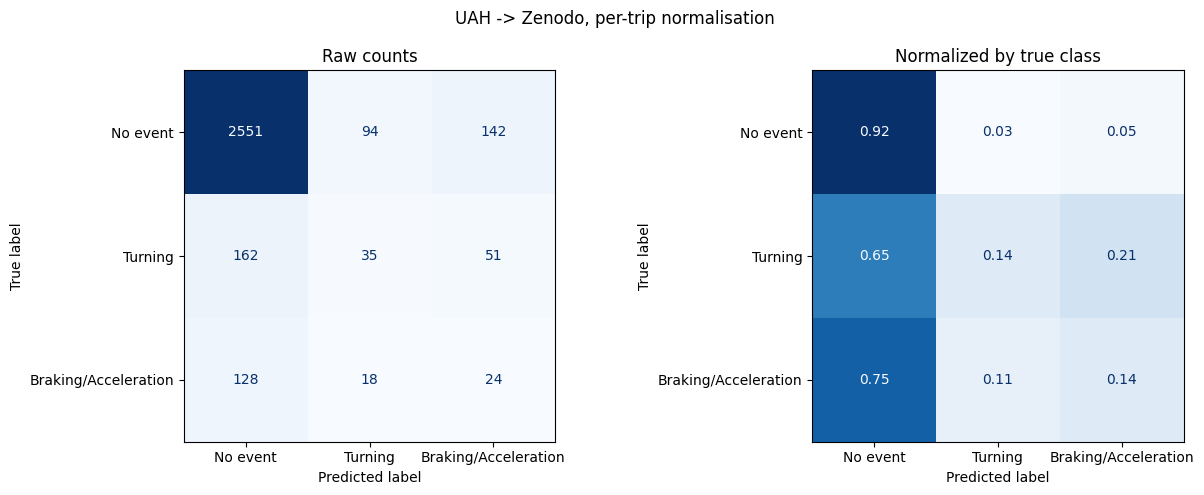

In [11]:
# ===== Cell 10: experiment C - per-trip normalisation (label-free) =====
# Idea: the two datasets differ mainly in sensor scale. Divide every feature by the MEDIAN of
# the same feature in the same trip (mostly ordinary driving), so each trip is measured against
# its own "normal". No labels are used, and nothing is fitted on Zenodo labels.
def trip_normalise(df, trips):
    out = df[FEATS].copy()
    for t in pd.unique(trips):
        m = (trips == t)
        med = df.loc[m, FEATS].median().abs() + 1e-6
        out.loc[m, FEATS] = df.loc[m, FEATS] / med
    return out

uah_n = trip_normalise(uah, uah.trip.values)
zen_n_all = trip_normalise(zen_all, zen_all.trip.values)          # medians use ALL windows of the trip
zen_n = zen_n_all[(zen_all.label >= 0).values].reset_index(drop=True)
assert len(zen_n) == len(zdf)

# reference inside UAH (unseen trips)
ref_n = []
for tr, te in GroupKFold(n_splits=3).split(uah_n, yu, gu):
    m_ = make_model().fit(uah_n.iloc[tr], yu[tr])
    ref_n.append(macro_f1(yu[te], m_.predict(uah_n.iloc[te])))
UAH_REF_C = float(np.mean(ref_n))

model_C = make_model().fit(uah_n, yu)          # trained on UAH only
predC = model_C.predict(zen_n)                 # zero-shot on Zenodo

summary_C = pd.concat([summary, pd.DataFrame([
    {"setting": "(UAH -> UAH, per-trip normalised, reference)", "macro_F1": UAH_REF_C, "balanced_acc": np.nan, "accuracy": np.nan},
    {"setting": "C) UAH -> Zenodo (per-trip normalisation)", "macro_F1": macro_f1(yz, predC),
     "balanced_acc": balanced_accuracy_score(yz, predC), "accuracy": accuracy_score(yz, predC)}])],
    ignore_index=True).round(4)
print(summary_C.to_string(index=False))
print("\n=== C) classification report ===")
print(classification_report(yz, predC, labels=LABELS, target_names=[CLASS_NAMES[i] for i in LABELS], zero_division=0))
plot_cm(yz, predC, "UAH -> Zenodo, per-trip normalisation", "confusion_zenodo_C_tripnorm.png")
summary_C.to_csv(OUT_DIR / "zenodo_generalization_summary_with_C.csv", index=False)